In [3]:
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import random
import time

# 실험 재현성을 위한 시드 고정
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU 사용 설정
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [4]:
import kagglehub

path = kagglehub.dataset_download(
    "mostafaabla/garbage-classification"
)

print("Dataset path:", path)
print("Folders:", os.listdir(path))

Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset path: /kaggle/input/garbage-classification
Folders: ['garbage_classification']


전체 이미지 수: 15515
클래스 수: 12
클래스 목록: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
      Class  Count  Ratio (%)
    battery    945       6.09
 biological    985       6.35
brown-glass    607       3.91
  cardboard    891       5.74
    clothes   5325      34.32
green-glass    629       4.05
      metal    769       4.96
      paper   1050       6.77
    plastic    865       5.58
      shoes   1977      12.74
      trash    697       4.49
white-glass    775       5.00


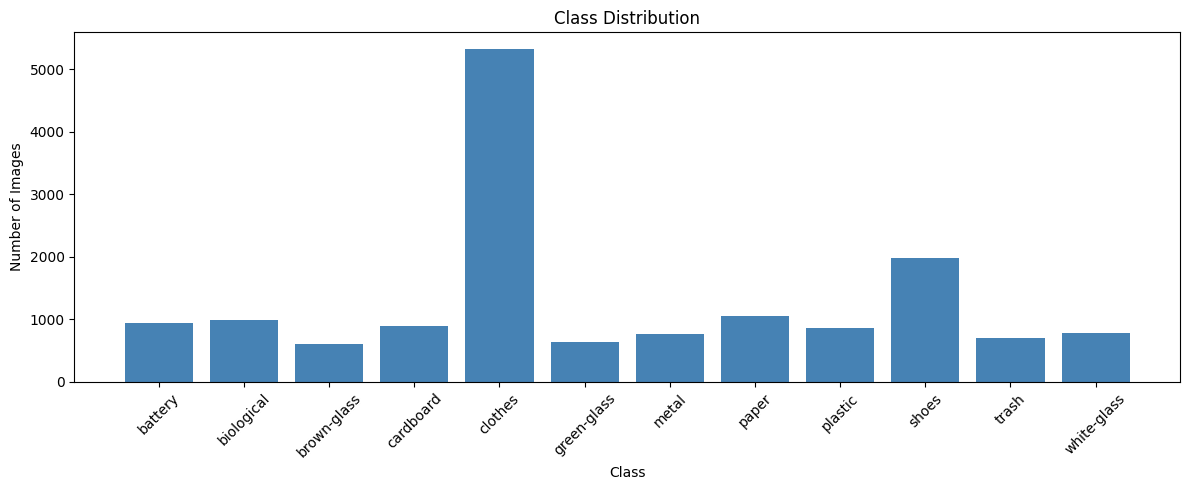

In [5]:
data_dir = os.path.join(path, "garbage_classification")

dataset = datasets.ImageFolder(data_dir)

class_names = dataset.classes
num_classes = len(class_names)

print("전체 이미지 수:", len(dataset))
print("클래스 수:", num_classes)
print("클래스 목록:", class_names)

df = pd.DataFrame({
    "Class": class_names,
    "Count": np.bincount(dataset.targets)
})

df["Ratio (%)"] = df["Count"] / len(dataset) * 100

print(df.round(2).to_string(index=False))

plt.figure(figsize=(12, 5))
plt.bar(df["Class"], df["Count"], color="steelblue")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

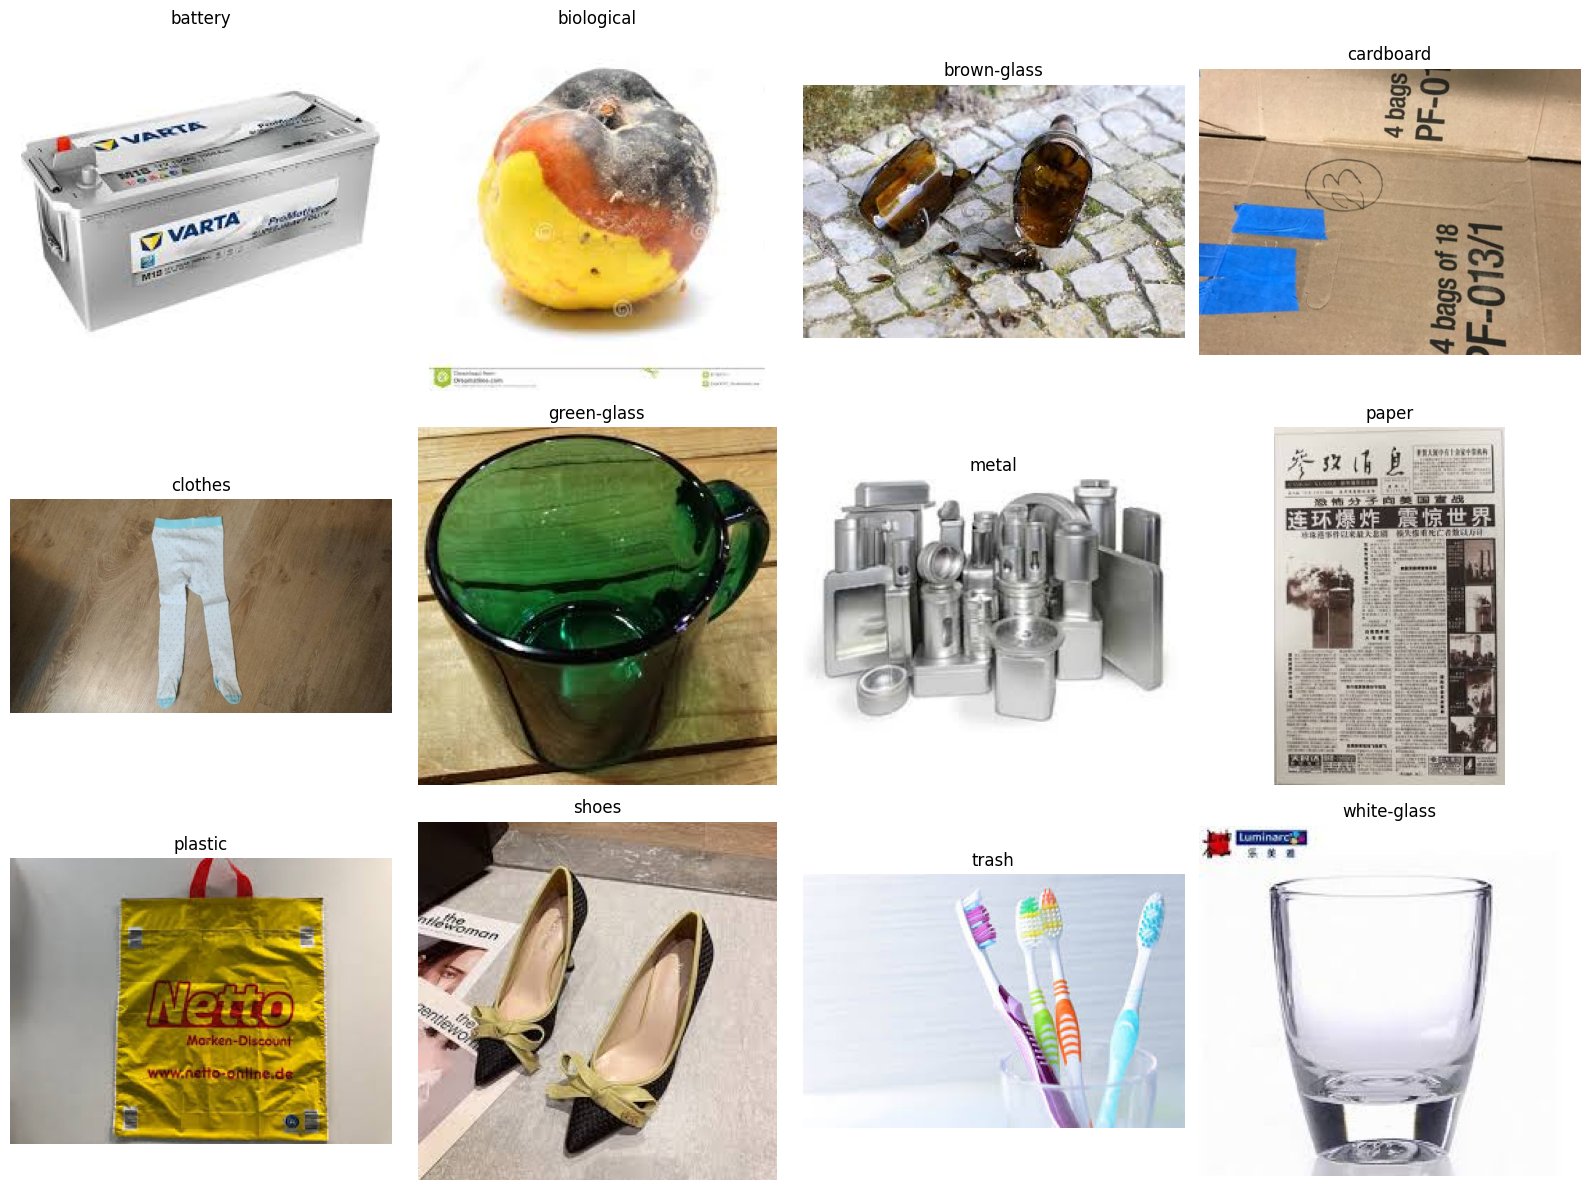

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

targets = np.array(dataset.targets)

for i, ax in enumerate(axes.flatten()):

    idx = np.random.choice(np.where(targets == i)[0])
    image, label = dataset[idx]

    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

        Width  Height
count  500.00  500.00
mean   352.29  356.92
std    121.53  150.97
min    111.00  129.00
25%    234.75  225.00
50%    400.00  384.00
75%    400.00  533.00
max    888.00  867.00


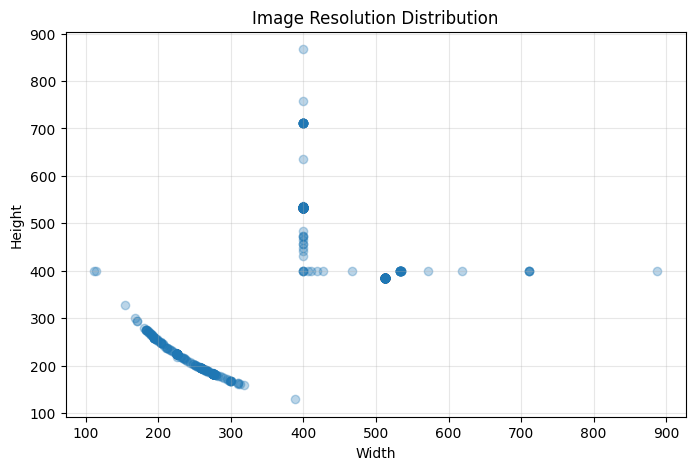

In [5]:
sizes = []

for idx in random.sample(range(len(dataset)), 500):
    image, label = dataset[idx]
    sizes.append(image.size)

size_df = pd.DataFrame(
    sizes, columns=["Width", "Height"]
)

print(size_df.describe().round(2))

plt.figure(figsize=(8, 5))
plt.scatter(size_df["Width"], size_df["Height"], alpha=0.3)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Resolution Distribution")
plt.grid(alpha=0.3)
plt.show()

In [6]:
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.3,
    stratify=targets,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=targets[temp_idx],
    random_state=42
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 10860
Validation: 2327
Test: 2328


In [7]:
IMG_SIZE = 128

base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

base_dataset = datasets.ImageFolder(
    data_dir, transform=base_transform
)

train_data = Subset(base_dataset, train_idx)
val_data = Subset(base_dataset, val_idx)
test_data = Subset(base_dataset, test_idx)

image, label = train_data[0]

print("Image shape:", image.shape)
print("Min:", image.min().item())
print("Max:", image.max().item())
print("Class:", class_names[label])

Image shape: torch.Size([3, 128, 128])
Min: -1.0
Max: 1.0
Class: biological


In [8]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Image shape:", images.shape)
print("Label shape:", labels.shape)

Train batches: 170
Validation batches: 37
Test batches: 37
Image shape: torch.Size([64, 3, 128, 128])
Label shape: torch.Size([64])


In [9]:
class BasicCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


baseline_model = BasicCNN().to(device)

print(baseline_model)

print("Parameters:",
      sum(p.numel() for p in baseline_model.parameters()))

with torch.no_grad():
    output = baseline_model(images.to(device))

print("Output shape:", output.shape)

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=12, bias=True)
  )
)
Parameters: 357068
Output shape: torch.Size([64, 12])


In [10]:
from sklearn.metrics import f1_score

def train_model(model, train_loader, val_loader,
                epochs=8, lr=0.001, weight=None):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss(weight=weight)
    val_criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = []
    best_f1 = -1
    best_state = None

    start_time = time.time()

    for epoch in range(epochs):

        # 학습
        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            output = model(x)
            loss = criterion(output, y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * y.size(0)
            train_correct += (output.argmax(1) == y).sum().item()
            train_total += y.size(0)

        # 검증
        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        predictions = []
        actual = []

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)

                output = model(x)
                loss = val_criterion(output, y)
                pred = output.argmax(1)

                val_loss += loss.item() * y.size(0)
                val_correct += (pred == y).sum().item()
                val_total += y.size(0)

                predictions.extend(pred.cpu().tolist())
                actual.extend(y.cpu().tolist())

        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        macro_f1 = f1_score(
            actual, predictions,
            average="macro",
            labels=list(range(num_classes)),
            zero_division=0
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss / train_total,
            "val_loss": val_loss / val_total,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "macro_f1": macro_f1
        })

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss/train_total:.4f} | "
            f"Val Loss: {val_loss/val_total:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"F1: {macro_f1:.4f}"
        )

    elapsed = time.time() - start_time

    model.load_state_dict(best_state)

    print(f"\nTraining Time: {elapsed:.2f}s")

    return model, pd.DataFrame(history), elapsed


# 기본 모델 학습
torch.manual_seed(SEED)
baseline_model = BasicCNN().to(device)

baseline_model, baseline_history, baseline_time = train_model(
    baseline_model,
    train_loader,
    val_loader,
    epochs=8,
    lr=0.001
)

Epoch 1/8 | Train Loss: 1.5785 | Val Loss: 1.2778 | Train Acc: 0.4831 | Val Acc: 0.5638 | F1: 0.4267
Epoch 2/8 | Train Loss: 1.1325 | Val Loss: 1.0514 | Train Acc: 0.6152 | Val Acc: 0.6498 | F1: 0.5676
Epoch 3/8 | Train Loss: 0.9669 | Val Loss: 0.9524 | Train Acc: 0.6726 | Val Acc: 0.6721 | F1: 0.5919
Epoch 4/8 | Train Loss: 0.8613 | Val Loss: 0.8905 | Train Acc: 0.7162 | Val Acc: 0.7052 | F1: 0.6340
Epoch 5/8 | Train Loss: 0.7763 | Val Loss: 0.8163 | Train Acc: 0.7451 | Val Acc: 0.7327 | F1: 0.6653
Epoch 6/8 | Train Loss: 0.6988 | Val Loss: 0.8052 | Train Acc: 0.7692 | Val Acc: 0.7314 | F1: 0.6525
Epoch 7/8 | Train Loss: 0.6512 | Val Loss: 0.7677 | Train Acc: 0.7807 | Val Acc: 0.7482 | F1: 0.6851
Epoch 8/8 | Train Loss: 0.5984 | Val Loss: 0.7422 | Train Acc: 0.7993 | Val Acc: 0.7611 | F1: 0.7064

Training Time: 297.44s


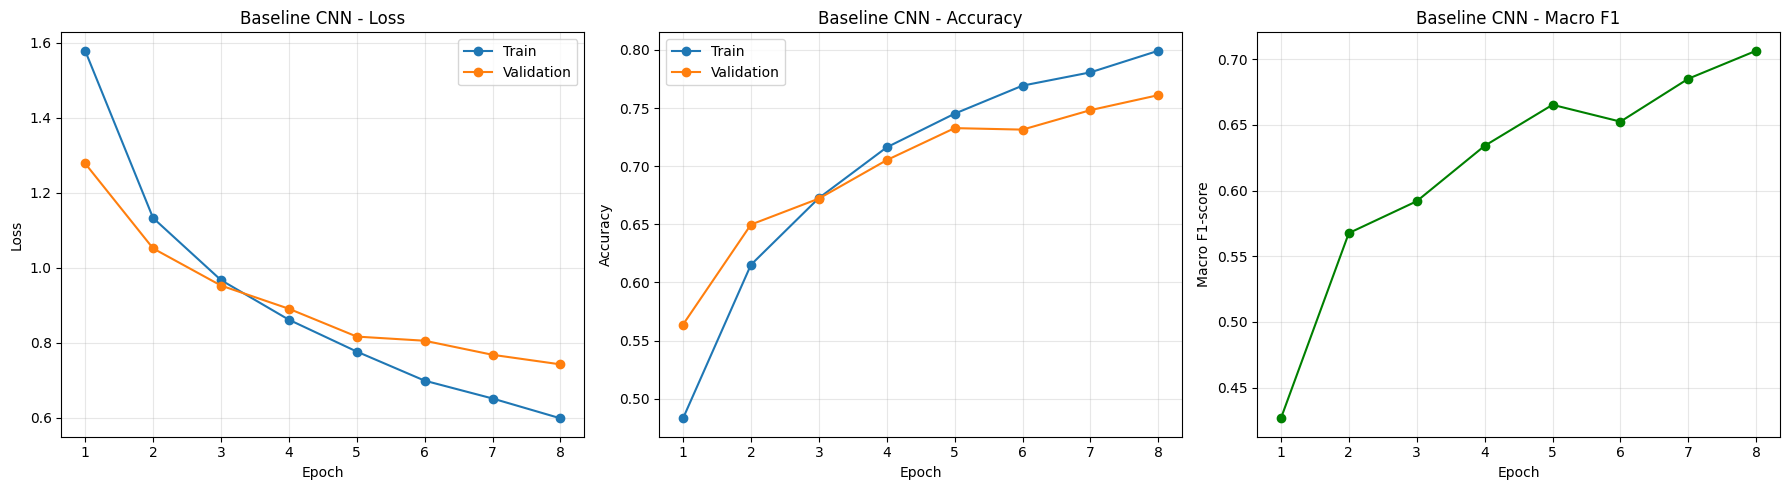

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 손실 곡선
axes[0].plot(baseline_history["epoch"],
             baseline_history["train_loss"],
             marker="o", label="Train")

axes[0].plot(baseline_history["epoch"],
             baseline_history["val_loss"],
             marker="o", label="Validation")

axes[0].set_title("Baseline CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 정확도 곡선
axes[1].plot(baseline_history["epoch"],
             baseline_history["train_acc"],
             marker="o", label="Train")

axes[1].plot(baseline_history["epoch"],
             baseline_history["val_acc"],
             marker="o", label="Validation")

axes[1].set_title("Baseline CNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

# Macro F1-score
axes[2].plot(baseline_history["epoch"],
             baseline_history["macro_f1"],
             marker="o", color="green")

axes[2].set_title("Baseline CNN - Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro F1-score")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
class RegularizedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


torch.manual_seed(SEED)

reg_model = RegularizedCNN().to(device)

reg_model, reg_history, reg_time = train_model(
    reg_model,
    train_loader,
    val_loader,
    epochs=8,
    lr=0.001
)

Epoch 1/8 | Train Loss: 1.3284 | Val Loss: 1.0905 | Train Acc: 0.5571 | Val Acc: 0.6231 | F1: 0.4895
Epoch 2/8 | Train Loss: 1.0534 | Val Loss: 0.9257 | Train Acc: 0.6568 | Val Acc: 0.6902 | F1: 0.5963
Epoch 3/8 | Train Loss: 0.9443 | Val Loss: 0.9273 | Train Acc: 0.6924 | Val Acc: 0.6846 | F1: 0.6015
Epoch 4/8 | Train Loss: 0.8607 | Val Loss: 0.8020 | Train Acc: 0.7142 | Val Acc: 0.7361 | F1: 0.6794
Epoch 5/8 | Train Loss: 0.8069 | Val Loss: 0.7802 | Train Acc: 0.7366 | Val Acc: 0.7499 | F1: 0.6751
Epoch 6/8 | Train Loss: 0.7560 | Val Loss: 0.7250 | Train Acc: 0.7481 | Val Acc: 0.7619 | F1: 0.6943
Epoch 7/8 | Train Loss: 0.7173 | Val Loss: 0.7320 | Train Acc: 0.7611 | Val Acc: 0.7615 | F1: 0.6924
Epoch 8/8 | Train Loss: 0.6762 | Val Loss: 0.6911 | Train Acc: 0.7790 | Val Acc: 0.7688 | F1: 0.7068

Training Time: 278.58s


In [13]:
aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

aug_dataset = datasets.ImageFolder(
    data_dir, transform=aug_transform
)

train_aug_data = Subset(aug_dataset, train_idx)

train_aug_loader = DataLoader(
    train_aug_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

torch.manual_seed(SEED)

aug_model = RegularizedCNN().to(device)

aug_model, aug_history, aug_time = train_model(
    aug_model,
    train_aug_loader,
    val_loader,
    epochs=8,
    lr=0.001
)

Epoch 1/8 | Train Loss: 1.4579 | Val Loss: 1.1961 | Train Acc: 0.5139 | Val Acc: 0.5922 | F1: 0.4525
Epoch 2/8 | Train Loss: 1.2030 | Val Loss: 1.0332 | Train Acc: 0.5960 | Val Acc: 0.6347 | F1: 0.5268
Epoch 3/8 | Train Loss: 1.0977 | Val Loss: 0.9404 | Train Acc: 0.6335 | Val Acc: 0.6889 | F1: 0.6107
Epoch 4/8 | Train Loss: 1.0319 | Val Loss: 0.9291 | Train Acc: 0.6584 | Val Acc: 0.6893 | F1: 0.6100
Epoch 5/8 | Train Loss: 0.9829 | Val Loss: 0.8696 | Train Acc: 0.6718 | Val Acc: 0.7035 | F1: 0.6056
Epoch 6/8 | Train Loss: 0.9419 | Val Loss: 0.8293 | Train Acc: 0.6889 | Val Acc: 0.7198 | F1: 0.6312
Epoch 7/8 | Train Loss: 0.9079 | Val Loss: 0.8835 | Train Acc: 0.6929 | Val Acc: 0.6953 | F1: 0.6058
Epoch 8/8 | Train Loss: 0.8809 | Val Loss: 0.7715 | Train Acc: 0.7085 | Val Acc: 0.7430 | F1: 0.6649

Training Time: 343.55s


In [7]:
for name in [
    "torch", "nn", "dataset", "train_loader",
    "train_model", "baseline_model", "reg_model",
    "aug_model", "baseline_history", "reg_history",
    "aug_history"
]:
    print(name, "OK" if name in globals() else "MISSING")

torch OK
nn OK
dataset OK
train_loader MISSING
train_model MISSING
baseline_model MISSING
reg_model MISSING
aug_model MISSING
baseline_history MISSING
reg_history MISSING
aug_history MISSING


In [9]:
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 64

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_dir = dataset.root
class_names = dataset.classes
num_classes = len(class_names)
targets = np.array(dataset.targets)

indices = np.arange(len(dataset))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.3,
    stratify=targets, random_state=SEED
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5,
    stratify=targets[temp_idx], random_state=SEED
)

base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

base_dataset = datasets.ImageFolder(
    data_dir, transform=base_transform
)

train_data = Subset(base_dataset, train_idx)
val_data = Subset(base_dataset, val_idx)
test_data = Subset(base_dataset, test_idx)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print("Device:", device)
print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("Recovery complete")

Device: cuda
Train: 10860
Validation: 2327
Test: 2328
Recovery complete


In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os

SAVE_DIR = "/content/drive/MyDrive/Trash_Classification"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Save directory:", SAVE_DIR)

Mounted at /content/drive
Save directory: /content/drive/MyDrive/Trash_Classification


In [11]:
import time
import pandas as pd
from sklearn.metrics import f1_score

def train_model(model, train_loader, val_loader,
                epochs=8, lr=0.001, weight=None,
                *, run_name):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss(weight=weight)
    val_criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = []
    best_f1 = -1
    best_state = None

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0
        train_loss_den = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            output = model(x)
            loss = criterion(output, y)
            loss.backward()
            optimizer.step()

            den = y.size(0) if weight is None else weight[y].sum().item()
            train_loss += loss.item() * den
            train_loss_den += den
            train_correct += (output.argmax(1) == y).sum().item()
            train_total += y.size(0)

        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        predictions = []
        actual = []

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)

                output = model(x)
                loss = val_criterion(output, y)
                pred = output.argmax(1)

                val_loss += loss.item() * y.size(0)
                val_correct += (pred == y).sum().item()
                val_total += y.size(0)

                predictions.extend(pred.cpu().tolist())
                actual.extend(y.cpu().tolist())

        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        macro_f1 = f1_score(
            actual, predictions,
            average="macro",
            labels=list(range(num_classes)),
            zero_division=0
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss / train_loss_den,
            "val_loss": val_loss / val_total,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "macro_f1": macro_f1
        })

        # 최적 모델 가중치 자동 저장
        if macro_f1 > best_f1:
            best_f1 = macro_f1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            torch.save(
                best_state,
                os.path.join(SAVE_DIR, f"{run_name}_best.pt")
            )

        # 학습 기록 자동 저장
        pd.DataFrame(history).to_csv(
            os.path.join(SAVE_DIR, f"{run_name}_history.csv"),
            index=False
        )

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss/train_loss_den:.4f} | "
            f"Val Loss: {val_loss/val_total:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"F1: {macro_f1:.4f}"
        )

    elapsed = time.time() - start_time

    model.load_state_dict(best_state)

    print(f"Training Time: {elapsed:.2f}s")

    return model, pd.DataFrame(history), elapsed


print("Training function restored")

Training function restored


In [12]:
class DeepCNN(nn.Module):
    def __init__(self):
        super().__init__()

        layers = []
        in_channels = 3

        for out_channels, num_convs in [
            (32, 1),
            (64, 2),
            (128, 2),
            (256, 2)
        ]:
            for _ in range(num_convs):
                layers.extend([
                    nn.Conv2d(in_channels, out_channels, 3, padding=1),
                    nn.BatchNorm2d(out_channels),
                    nn.ReLU()
                ])
                in_channels = out_channels

            layers.append(nn.MaxPool2d(2))

        layers.append(nn.AdaptiveAvgPool2d((4, 4)))

        self.features = nn.Sequential(*layers)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(SEED)

deep_model = DeepCNN().to(device)

deep_model, deep_history, deep_time = train_model(
    deep_model,
    train_loader,
    val_loader,
    epochs=8,
    lr=0.001,
    run_name="deep_cnn"
)

Epoch 1/8 | Train Loss: 1.5216 | Val Loss: 1.5121 | Train Acc: 0.5026 | Val Acc: 0.5398 | F1: 0.3788
Epoch 2/8 | Train Loss: 1.1828 | Val Loss: 1.2609 | Train Acc: 0.6092 | Val Acc: 0.6145 | F1: 0.5161
Epoch 3/8 | Train Loss: 1.0707 | Val Loss: 1.0142 | Train Acc: 0.6459 | Val Acc: 0.6652 | F1: 0.5451
Epoch 4/8 | Train Loss: 0.9770 | Val Loss: 0.8990 | Train Acc: 0.6822 | Val Acc: 0.6949 | F1: 0.6054
Epoch 5/8 | Train Loss: 0.9111 | Val Loss: 0.8757 | Train Acc: 0.7035 | Val Acc: 0.7129 | F1: 0.6214
Epoch 6/8 | Train Loss: 0.8646 | Val Loss: 0.8558 | Train Acc: 0.7184 | Val Acc: 0.7078 | F1: 0.6170
Epoch 7/8 | Train Loss: 0.8163 | Val Loss: 0.7633 | Train Acc: 0.7281 | Val Acc: 0.7503 | F1: 0.6742
Epoch 8/8 | Train Loss: 0.7893 | Val Loss: 0.8249 | Train Acc: 0.7397 | Val Acc: 0.7495 | F1: 0.6673
Training Time: 354.53s


In [13]:
tuned_model = DeepCNN().to(device)

tuned_model.load_state_dict(
    torch.load(
        os.path.join(SAVE_DIR, "deep_cnn_best.pt"),
        map_location=device,
        weights_only=True
    )
)

tuned_model, tuned_history, tuned_time = train_model(
    tuned_model,
    train_loader,
    val_loader,
    epochs=8,
    lr=0.0003,
    run_name="deep_cnn_tuned"
)

Epoch 1/8 | Train Loss: 0.7023 | Val Loss: 0.6798 | Train Acc: 0.7692 | Val Acc: 0.7714 | F1: 0.7052
Epoch 2/8 | Train Loss: 0.6393 | Val Loss: 0.6561 | Train Acc: 0.7886 | Val Acc: 0.7877 | F1: 0.7243
Epoch 3/8 | Train Loss: 0.6124 | Val Loss: 0.6504 | Train Acc: 0.7969 | Val Acc: 0.7877 | F1: 0.7232
Epoch 4/8 | Train Loss: 0.5866 | Val Loss: 0.6428 | Train Acc: 0.8073 | Val Acc: 0.7959 | F1: 0.7365
Epoch 5/8 | Train Loss: 0.5707 | Val Loss: 0.6160 | Train Acc: 0.8083 | Val Acc: 0.8023 | F1: 0.7465
Epoch 6/8 | Train Loss: 0.5457 | Val Loss: 0.6427 | Train Acc: 0.8184 | Val Acc: 0.8023 | F1: 0.7457
Epoch 7/8 | Train Loss: 0.5238 | Val Loss: 0.6168 | Train Acc: 0.8236 | Val Acc: 0.8040 | F1: 0.7438
Epoch 8/8 | Train Loss: 0.5042 | Val Loss: 0.5590 | Train Acc: 0.8322 | Val Acc: 0.8217 | F1: 0.7723
Training Time: 322.99s


In [14]:
class_counts = np.bincount(
    targets[train_idx],
    minlength=num_classes
)

weights = np.sqrt(class_counts.mean() / class_counts)
weights = weights / weights.mean()

class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

weighted_model = DeepCNN().to(device)

weighted_model.load_state_dict(
    torch.load(
        os.path.join(SAVE_DIR, "deep_cnn_tuned_best.pt"),
        map_location=device,
        weights_only=True
    )
)

weighted_model, weighted_history, weighted_time = train_model(
    weighted_model,
    train_loader,
    val_loader,
    epochs=6,
    lr=0.0003,
    weight=class_weights,
    run_name="deep_cnn_weighted"
)

Epoch 1/6 | Train Loss: 0.5915 | Val Loss: 0.6097 | Train Acc: 0.8305 | Val Acc: 0.8088 | F1: 0.7563
Epoch 2/6 | Train Loss: 0.5545 | Val Loss: 0.5678 | Train Acc: 0.8401 | Val Acc: 0.8199 | F1: 0.7669
Epoch 3/6 | Train Loss: 0.5348 | Val Loss: 0.5783 | Train Acc: 0.8403 | Val Acc: 0.8161 | F1: 0.7656
Epoch 4/6 | Train Loss: 0.5219 | Val Loss: 0.5715 | Train Acc: 0.8478 | Val Acc: 0.8225 | F1: 0.7730
Epoch 5/6 | Train Loss: 0.5027 | Val Loss: 0.6374 | Train Acc: 0.8529 | Val Acc: 0.7993 | F1: 0.7457
Epoch 6/6 | Train Loss: 0.4842 | Val Loss: 0.5782 | Train Acc: 0.8599 | Val Acc: 0.8161 | F1: 0.7665
Training Time: 241.06s


In [15]:
control_model = DeepCNN().to(device)

control_model.load_state_dict(
    torch.load(
        os.path.join(SAVE_DIR, "deep_cnn_tuned_best.pt"),
        map_location=device,
        weights_only=True
    )
)

control_model, control_history, control_time = train_model(
    control_model,
    train_loader,
    val_loader,
    epochs=6,
    lr=0.0003,
    run_name="deep_cnn_control"
)

Epoch 1/6 | Train Loss: 0.4930 | Val Loss: 0.5790 | Train Acc: 0.8337 | Val Acc: 0.8169 | F1: 0.7662
Epoch 2/6 | Train Loss: 0.4649 | Val Loss: 0.5630 | Train Acc: 0.8466 | Val Acc: 0.8195 | F1: 0.7665
Epoch 3/6 | Train Loss: 0.4495 | Val Loss: 0.5520 | Train Acc: 0.8483 | Val Acc: 0.8251 | F1: 0.7746
Epoch 4/6 | Train Loss: 0.4353 | Val Loss: 0.5573 | Train Acc: 0.8512 | Val Acc: 0.8285 | F1: 0.7779
Epoch 5/6 | Train Loss: 0.4162 | Val Loss: 0.5876 | Train Acc: 0.8581 | Val Acc: 0.8131 | F1: 0.7550
Epoch 6/6 | Train Loss: 0.4065 | Val Loss: 0.5547 | Train Acc: 0.8607 | Val Acc: 0.8242 | F1: 0.7730
Training Time: 242.15s


In [16]:
from sklearn.metrics import accuracy_score, f1_score

final_model = DeepCNN().to(device)

final_model.load_state_dict(
    torch.load(
        os.path.join(SAVE_DIR, "deep_cnn_control_best.pt"),
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

test_actual = []
test_predictions = []
test_confidences = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        output = final_model(x)
        probs = torch.softmax(output, dim=1)
        confidence, pred = probs.max(dim=1)

        test_actual.extend(y.tolist())
        test_predictions.extend(pred.cpu().tolist())
        test_confidences.extend(confidence.cpu().tolist())

test_acc = accuracy_score(test_actual, test_predictions)

test_f1 = f1_score(
    test_actual, test_predictions,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy: {test_acc:.4%}")
print(f"Test Macro F1: {test_f1:.4%}")
print("Test Images:", len(test_actual))

Test Accuracy: 83.2045%
Test Macro F1: 78.9901%
Test Images: 2328


              precision    recall  f1-score   support

     battery     0.8304    0.6549    0.7323       142
  biological     0.7898    0.8378    0.8131       148
 brown-glass     0.8642    0.7692    0.8140        91
   cardboard     0.8992    0.7985    0.8458       134
     clothes     0.9091    0.9512    0.9297       799
 green-glass     0.8830    0.8830    0.8830        94
       metal     0.6754    0.6696    0.6725       115
       paper     0.7977    0.8734    0.8338       158
     plastic     0.6585    0.6231    0.6403       130
       shoes     0.7538    0.8350    0.7923       297
       trash     0.7857    0.7404    0.7624       104
 white-glass     0.8587    0.6810    0.7596       116

    accuracy                         0.8320      2328
   macro avg     0.8088    0.7764    0.7899      2328
weighted avg     0.8324    0.8320    0.8301      2328



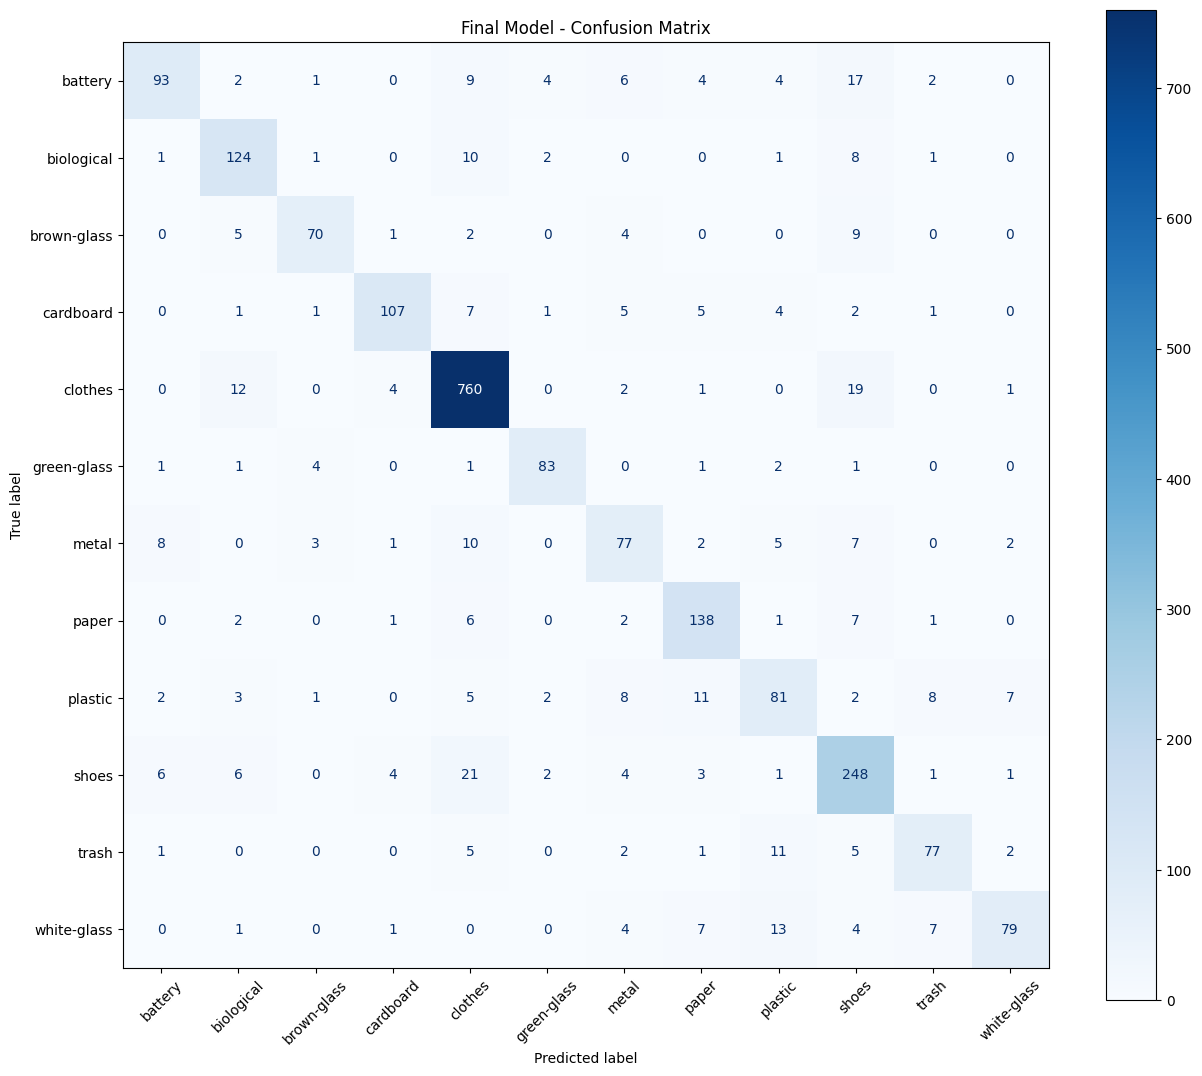

In [17]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

print(classification_report(
    test_actual,
    test_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(13, 11))

ConfusionMatrixDisplay.from_predictions(
    test_actual,
    test_predictions,
    labels=list(range(num_classes)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Final Model - Confusion Matrix")
plt.tight_layout()
plt.show()

shoes -> clothes: 21 images
clothes -> shoes: 19 images
battery -> shoes: 17 images
white-glass -> plastic: 13 images
clothes -> biological: 12 images


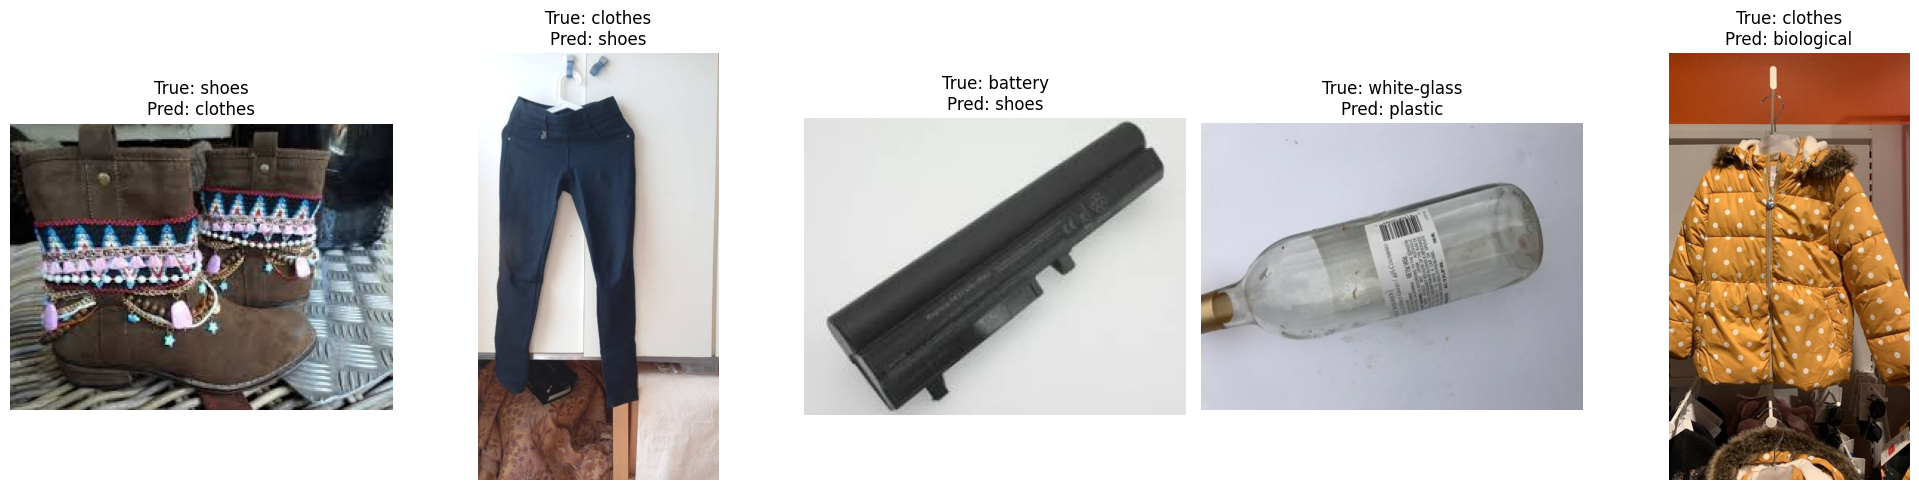

In [18]:
from sklearn.metrics import confusion_matrix

actual = np.array(test_actual)
predicted = np.array(test_predictions)

cm = confusion_matrix(
    actual, predicted,
    labels=list(range(num_classes))
)

np.fill_diagonal(cm, 0)

top_errors = np.argsort(cm.ravel())[::-1][:5]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, pair in zip(axes, top_errors):

    true_class, pred_class = np.unravel_index(
        pair, cm.shape
    )

    print(
        f"{class_names[true_class]} -> "
        f"{class_names[pred_class]}: "
        f"{cm[true_class, pred_class]} images"
    )

    pos = np.where(
        (actual == true_class) &
        (predicted == pred_class)
    )[0][0]

    image, _ = dataset[int(test_idx[pos])]

    ax.imshow(image)
    ax.set_title(
        f"True: {class_names[true_class]}\n"
        f"Pred: {class_names[pred_class]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
confidence = np.array(test_confidences)
correct = np.array(test_actual) == np.array(test_predictions)

results = []

for threshold in [0.0, 0.6, 0.7, 0.8, 0.9, 0.95]:

    accepted = confidence >= threshold

    results.append({
        "Threshold": threshold,
        "Coverage (%)": accepted.mean() * 100,
        "Accuracy (%)": correct[accepted].mean() * 100
                        if accepted.any() else np.nan,
        "Accepted": accepted.sum(),
        "Deferred": (~accepted).sum()
    })

confidence_df = pd.DataFrame(results)

print(confidence_df.round(2).to_string(index=False))

 Threshold  Coverage (%)  Accuracy (%)  Accepted  Deferred
      0.00        100.00         83.20      2328         0
      0.60         83.93         89.66      1954       374
      0.70         77.88         91.56      1813       515
      0.80         70.83         93.27      1649       679
      0.90         61.13         95.50      1423       905
      0.95         53.74         96.64      1251      1077


In [20]:
FINAL_PATH = os.path.join(SAVE_DIR, "final_trash_cnn.pt")

torch.save({
    "model_state_dict": {
        k: v.detach().cpu().clone()
        for k, v in final_model.state_dict().items()
    },
    "architecture": "DeepCNN",
    "class_names": class_names,
    "num_classes": num_classes,
    "image_size": IMG_SIZE,
    "mean": [0.5, 0.5, 0.5],
    "std": [0.5, 0.5, 0.5]
}, FINAL_PATH)

print("Saved:", FINAL_PATH)
print("File size:", round(os.path.getsize(FINAL_PATH) / 1024**2, 2), "MB")

Saved: /content/drive/MyDrive/Trash_Classification/final_trash_cnn.pt
File size: 6.47 MB


In [21]:
checkpoint = torch.load(
    FINAL_PATH,
    map_location=device,
    weights_only=True
)

loaded_model = DeepCNN().to(device)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

inference_transform = transforms.Compose([
    transforms.Resize((
        checkpoint["image_size"],
        checkpoint["image_size"]
    )),
    transforms.ToTensor(),
    transforms.Normalize(
        checkpoint["mean"],
        checkpoint["std"]
    )
])

with torch.no_grad():
    dummy = torch.zeros(1, 3, 128, 128).to(device)
    output = loaded_model(dummy)

print("Model loaded successfully")
print("Architecture:", checkpoint["architecture"])
print("Classes:", checkpoint["class_names"])
print("Output shape:", output.shape)
print("Device:", device)

Model loaded successfully
Architecture: DeepCNN
Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Output shape: torch.Size([1, 12])
Device: cuda


Saving pt.png to pt.png
Saving 박스.png to 박스.png
Saving 신발.png to 신발.png
Saving 옷.png to 옷.png


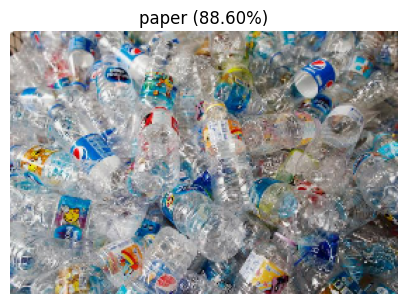

File: pt.png
paper: 88.60%
plastic: 7.16%
cardboard: 1.90%
Decision: Automatic classification
----------------------------------------


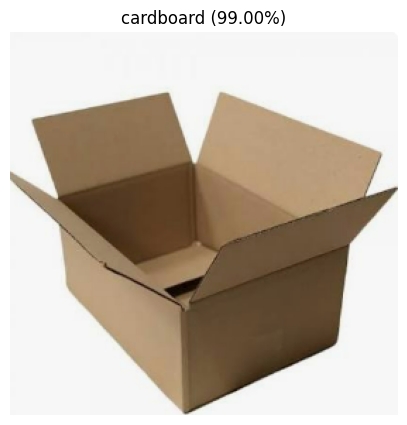

File: 박스.png
cardboard: 99.00%
brown-glass: 0.72%
shoes: 0.24%
Decision: Automatic classification
----------------------------------------


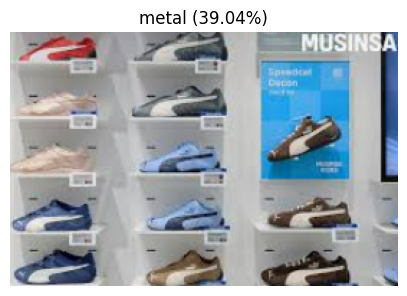

File: 신발.png
metal: 39.04%
plastic: 21.13%
white-glass: 12.93%
Decision: Manual inspection required
----------------------------------------


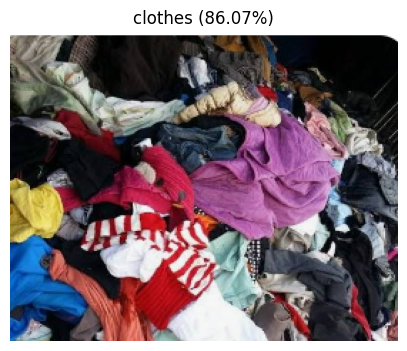

File: 옷.png
clothes: 86.07%
paper: 9.05%
biological: 2.18%
Decision: Automatic classification
----------------------------------------


In [22]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

for filename, content in uploaded.items():

    image = Image.open(io.BytesIO(content)).convert("RGB")

    x = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = loaded_model(x)
        probs = torch.softmax(output, dim=1)

    scores, indices = torch.topk(probs[0], 3)

    confidence = scores[0].item()
    prediction = checkpoint["class_names"][indices[0].item()]

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(f"{prediction} ({confidence:.2%})")
    plt.axis("off")
    plt.show()

    print("File:", filename)

    for score, idx in zip(scores, indices):
        print(
            f"{checkpoint['class_names'][idx.item()]}: "
            f"{score.item():.2%}"
        )

    if confidence >= 0.8:
        print("Decision: Automatic classification")
    else:
        print("Decision: Manual inspection required")

    print("-" * 40)

In [23]:
import time

sample, _ = test_data[0]
sample = sample.unsqueeze(0).to(device)

loaded_model.eval()
inference_times = []

with torch.no_grad():

    # GPU 예열
    for _ in range(20):
        loaded_model(sample)

    if device.type == "cuda":
        torch.cuda.synchronize()

    # 100회 추론 속도 측정
    for _ in range(100):

        start = time.perf_counter()

        loaded_model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

        inference_times.append((end - start) * 1000)

avg_ms = np.mean(inference_times)

print(f"Average Latency: {avg_ms:.2f} ms")
print(f"Median Latency: {np.median(inference_times):.2f} ms")
print(f"P95 Latency: {np.percentile(inference_times, 95):.2f} ms")
print(f"Theoretical FPS: {1000 / avg_ms:.2f}")

Average Latency: 3.23 ms
Median Latency: 2.42 ms
P95 Latency: 6.19 ms
Theoretical FPS: 309.52


In [24]:
from google.colab import files

files.download(FINAL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>